# P1 — Classificação de Tumores Cerebrais com ConvNeXt-Atto

**Prática:** estruturar o pipeline reprodutível de classificação multiclasse (*glioma*, *meningioma*, *notumor*, *pituitary*) utilizando as imagens completas do dataset no Google Drive, treinar e avaliar na **validação** e no **teste**, e exportar os resultados experimentais e as matrizes de confusão em `matplotlib` (`plt`).

**Entregáveis gerados no Drive (`MyDrive/Brain_Tumor_Project`):** `splits.csv`, `P1_classificacao.xlsx`, `best_convnext_atto_full_img.pth` e as figuras `matriz_confusao_*.png`. A resolução de entrada é **224 × 224**; a avaliação usa o **Macro F1-Score** como critério de seleção.

## Galeria de classes e padronização de entrada

O dataset utilizado está organizado em `DATASET/classification/` com as partições originais `Training/` e `Testing/`, distribuídas em quatro classes clínicas: **`glioma`**, **`meningioma`**, **`notumor`** e **`pituitary`**.

### Atenção aos canais de cor (RGB) e reprodutibilidade

As imagens de ressonância magnética (MRI) podem estar armazenadas em escala de cinza (1 canal) ou RGB (3 canais) com dimensões variadas. Todas as amostras são convertidas explicitamente para **RGB (3 canais)**, redimensionadas via interpolação **bilinear** para **224 × 224** e normalizadas com a média e o desvio padrão do *ImageNet* para compatibilidade com os pesos pré-treinados da `ConvNeXt-Atto`.

As próximas células geram uma inspeção visual ao vivo das partições e garantem que a divisão salva em **`splits.csv`** permaneça fixa para as etapas seguintes do artigo (segmentação com **SegFormer** e **Knowledge Distillation**).

## 1. Configuração, montagem do Drive e cópia local rápida

Usaremos a pasta **já existente** `MyDrive/Brain_Tumor_Project` para salvar todos os entregáveis (`splits.csv`, `P1_classificacao.xlsx`, matrizes `.png` e pesos `.pth`). Para evitar lentidão de leitura de milhares de arquivos diretamente pelo Google Drive durante o treinamento, copiamos `DATASET/classification` para o disco local temporário do Colab (`/content/dataset_classification`), mantendo as partições originais intactas.

In [9]:
!pip install -q timm openpyxl

from pathlib import Path
import os
import shutil
import random
import hashlib
import time
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from PIL import Image

try:
    from google.colab import drive
    NO_COLAB = True
except ImportError:
    NO_COLAB = False

if NO_COLAB and not os.environ.get('BT_BASE_DIR'):
    drive.mount('/content/drive')

PROJETO_DIR = Path(os.environ.get('BT_PROJECT_DIR', '/content/drive/MyDrive/Brain_Tumor_Project'))
DRIVE_CLASSIF = Path(os.environ.get('BT_BASE_DIR', PROJETO_DIR / 'DATASET' / 'classification'))
LOCAL_BASE = Path('/content/dataset_classification')

ALTURA, LARGURA = 224, 224
SEED = 42
BATCH_SIZE = 32
EPOCAS = int(os.environ.get('BT_EPOCAS', 25))  # 25 na GPU (~2-4 min); em CPU reduza para 10–12.
LR = 1e-4
VERSAO_MODELO = 'convnext_atto_full_img_v1'

if not DRIVE_CLASSIF.is_dir():
    raise FileNotFoundError(
        f'Dataset ausente em: {DRIVE_CLASSIF}. '
        'Verifique se o atalho de Brain_Tumor_Project está adicionado em Meu Drive.'
    )

if not LOCAL_BASE.exists():
    print('Copiando dataset para o disco local do Colab (acelera leitura nas épocas)...')
    shutil.copytree(DRIVE_CLASSIF, LOCAL_BASE)

PROJETO_DIR.mkdir(parents=True, exist_ok=True)
print('PROJETO_DIR:', PROJETO_DIR)
print('LOCAL_BASE:', LOCAL_BASE)
print('Épocas máximas:', EPOCAS)


Drive already mounted at /content/drive; to attempt to forcibly remount, call drive.mount("/content/drive", force_remount=True).
PROJETO_DIR: /content/drive/MyDrive/Brain_Tumor_Project
LOCAL_BASE: /content/dataset_classification
Épocas máximas: 25


## 2. Particionamento estratificado (`splits.csv`) e checagem de integridade

Cada registro entregue ao modelo deve conter o **caminho da imagem e seu rótulo correspondente**, sem vazamento entre partições. O código abaixo:
* Mantém a pasta `Testing/` original como conjunto de **teste (`test`)**.
* Divide a pasta `Training/` de forma estratificada em **treino (`train` — 85%)** e **validação (`val` — 15%)**.
* Garante compatibilidade caso já exista um `splits.csv` gerado anteriormente no Drive e verifica se os IDs são disjuntos entre `train`, `val` e `test`.

In [10]:
from sklearn.model_selection import train_test_split

EXTENSOES = {'.png', '.jpg', '.jpeg', '.tif', '.tiff', '.bmp'}
SPLITS_PATH = PROJETO_DIR / 'splits.csv'

def indexar_pasta(pasta_split):
    registros = []
    classes = sorted([d.name for d in pasta_split.iterdir() if d.is_dir()])
    for classe in classes:
        for arquivo in sorted((pasta_split / classe).glob('*')):
            if arquivo.is_file() and arquivo.suffix.lower() in EXTENSOES:
                rel_path = f'{pasta_split.name}/{classe}/{arquivo.name}'
                ident = f'{pasta_split.name}_{classe}_{arquivo.stem}'
                registros.append({
                    'id': ident,
                    'rel_path': rel_path,
                    'label': classe
                })
    return registros

def carregar_ou_criar_splits():
    if SPLITS_PATH.is_file():
        df = pd.read_csv(SPLITS_PATH)
        print(f'Partições reutilizadas de {SPLITS_PATH}.')
        # Garante compatibilidade com splits.csv gerados na versão anterior (sem coluna id)
        if 'id' not in df.columns:
            df['id'] = df['rel_path'].apply(
                lambda p: f"{Path(p).parts[0]}_{Path(p).parts[1]}_{Path(p).stem}"
            )
            df.to_csv(SPLITS_PATH, index=False)
            print('Coluna id adicionada e atualizada em splits.csv.')
    else:
        reg_train_val = indexar_pasta(LOCAL_BASE / 'Training')
        reg_test = indexar_pasta(LOCAL_BASE / 'Testing')
        if not reg_train_val or not reg_test:
            raise FileNotFoundError(f'Imagens ausentes em {LOCAL_BASE}')

        df_tv = pd.DataFrame(reg_train_val)
        df_te = pd.DataFrame(reg_test)
        df_te['split'] = 'test'

        df_tr, df_va = train_test_split(
            df_tv, test_size=0.15, stratify=df_tv['label'], random_state=SEED
        )
        df_tr = df_tr.copy()
        df_va = df_va.copy()
        df_tr['split'] = 'train'
        df_va['split'] = 'val'

        df = pd.concat([df_tr, df_va, df_te], ignore_index=True)
        df.to_csv(SPLITS_PATH, index=False)
        print(f'Novo splits.csv salvo em {SPLITS_PATH}.')

    # Checagem de partições disjuntas
    ids_por_split = {s: set(df[df['split'] == s]['id']) for s in ('train', 'val', 'test')}
    for a, b in [('train', 'val'), ('train', 'test'), ('val', 'test')]:
        if ids_por_split[a] & ids_por_split[b]:
            raise ValueError(f'IDs repetidos entre {a} e {b}; verifique splits.csv.')

    df['filepath'] = df['rel_path'].apply(lambda p: str(LOCAL_BASE / p))
    return df

df_splits = carregar_ou_criar_splits()
CLASSES = sorted(df_splits['label'].unique())
CLASS_TO_IDX = {c: i for i, c in enumerate(CLASSES)}
IDX_TO_CLASS = {i: c for c, i in CLASS_TO_IDX.items()}

print({s: int((df_splits['split'] == s).sum()) for s in ('train', 'val', 'test')})
print('IDs disjuntos; classes indexadas:', CLASS_TO_IDX)


Partições reutilizadas de /content/drive/MyDrive/Brain_Tumor_Project/splits.csv.
{'train': 4855, 'val': 857, 'test': 1311}
IDs disjuntos; classes indexadas: {'glioma': 0, 'meningioma': 1, 'notumor': 2, 'pituitary': 3}


In [11]:
import torch
from torch import nn
from torch.utils.data import Dataset, DataLoader
from torchvision import transforms
from collections import Counter
import timm

random.seed(SEED)
np.random.seed(SEED)
torch.manual_seed(SEED)
if torch.cuda.is_available():
    torch.cuda.manual_seed_all(SEED)
device = torch.device('cuda' if torch.cuda.is_available() else 'cpu')
print('Dispositivo:', device)
if device.type != 'cuda':
    print('AVISO: GPU não detectada! Ative em Ambiente de execução -> Alterar tipo -> T4 GPU.')

# Assinatura SHA-256 do splits.csv para rastreabilidade experimental
ASSINATURA = hashlib.sha256(SPLITS_PATH.read_bytes()).hexdigest()
print('Assinatura splits.csv:', ASSINATURA[:16])

transform_treino = transforms.Compose([
    transforms.Resize((ALTURA, LARGURA), interpolation=transforms.InterpolationMode.BILINEAR),
    transforms.RandomHorizontalFlip(p=0.5),
    transforms.RandomRotation(10),
    transforms.ToTensor(),
    transforms.Normalize(mean=[0.485, 0.456, 0.406], std=[0.229, 0.224, 0.225])
])

transform_eval = transforms.Compose([
    transforms.Resize((ALTURA, LARGURA), interpolation=transforms.InterpolationMode.BILINEAR),
    transforms.ToTensor(),
    transforms.Normalize(mean=[0.485, 0.456, 0.406], std=[0.229, 0.224, 0.225])
])

class DatasetClassificacao(Dataset):
    def __init__(self, df_particao, transform):
        self.df = df_particao.reset_index(drop=True)
        self.ids = self.df['id'].tolist()
        self.labels = self.df['label'].tolist()
        self.paths = self.df['filepath'].tolist()
        self.transform = transform

    def __len__(self):
        return len(self.df)

    def __getitem__(self, indice):
        with Image.open(self.paths[indice]) as arquivo:
            imagem_pil = arquivo.convert('RGB')
        x = self.transform(imagem_pil)
        y = CLASS_TO_IDX[self.labels[indice]]
        return x, y, self.ids[indice]


Dispositivo: cuda
Assinatura splits.csv: 6fbf0e16c360ac4f


In [12]:
dataset_treino = DatasetClassificacao(df_splits[df_splits['split'] == 'train'], transform_treino)
dataset_val = DatasetClassificacao(df_splits[df_splits['split'] == 'val'], transform_eval)
dataset_teste = DatasetClassificacao(df_splits[df_splits['split'] == 'test'], transform_eval)

# num_workers=0 evita travamentos de multiprocessamento no Google Colab
loader_treino = DataLoader(dataset_treino, batch_size=BATCH_SIZE, shuffle=True, num_workers=0, pin_memory=(device.type == 'cuda'))
loader_val = DataLoader(dataset_val, batch_size=BATCH_SIZE, shuffle=False, num_workers=0, pin_memory=(device.type == 'cuda'))
loader_teste = DataLoader(dataset_teste, batch_size=BATCH_SIZE, shuffle=False, num_workers=0, pin_memory=(device.type == 'cuda'))

for rotulo, ds in [('Treino', dataset_treino), ('Validação', dataset_val), ('Teste', dataset_teste)]:
    print(f'{rotulo}: {len(ds)} imagens | distribuição:', dict(sorted(Counter(ds.labels).items())))

imagens, alvos, ids = next(iter(loader_treino))
print('Amostra de IDs:', list(ids[:4]))
print('Tensor imagem:', tuple(imagens.shape), imagens.dtype)
print('Tensor rótulos:', tuple(alvos.shape), alvos.dtype, alvos[:4].tolist())
assert imagens.shape[1:] == (3, ALTURA, LARGURA)


Treino: 4855 imagens | distribuição: {'glioma': 1123, 'meningioma': 1138, 'notumor': 1356, 'pituitary': 1238}
Validação: 857 imagens | distribuição: {'glioma': 198, 'meningioma': 201, 'notumor': 239, 'pituitary': 219}
Teste: 1311 imagens | distribuição: {'glioma': 300, 'meningioma': 306, 'notumor': 405, 'pituitary': 300}
Amostra de IDs: ['Training_glioma_enh_Tr-gl_0261', 'Training_notumor_enh_Tr-noTr_0008', 'Training_glioma_enh_Tr-gl_0377', 'Training_notumor_enh_Tr-no_0477']
Tensor imagem: (32, 3, 224, 224) torch.float32
Tensor rótulos: (32,) torch.int64 [0, 2, 0, 2]


### Inspeção ao vivo: uma amostra real por classe da partição `val/`

Antes de iniciar o treinamento, visualizamos com `matplotlib` (`plt`) um exemplo real de cada classe presente na partição de validação (`glioma`, `meningioma`, `notumor`, `pituitary`), exibindo as dimensões originais da imagem e o rótulo associado.

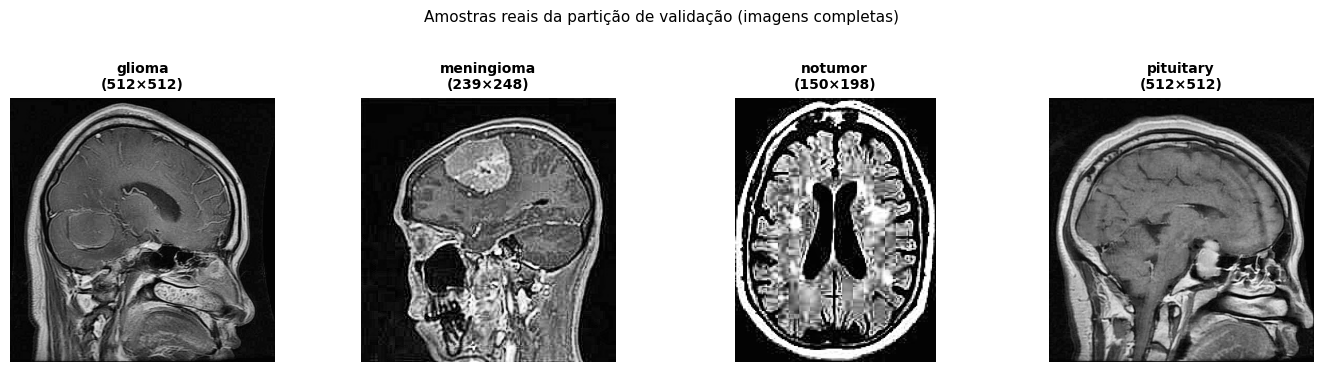

In [13]:
fig, axes = plt.subplots(1, len(CLASSES), figsize=(14, 3.6))
df_val_vis = df_splits[df_splits['split'] == 'val']

for idx, classe in enumerate(CLASSES):
    linha = df_val_vis[df_val_vis['label'] == classe].iloc[0]
    with Image.open(linha['filepath']) as img:
        orig_size = img.size
        img_arr = np.asarray(img.convert('RGB'))
    axes[idx].imshow(img_arr)
    axes[idx].set_title(f'{classe}\n({orig_size[0]}×{orig_size[1]})', fontsize=10, fontweight='bold')
    axes[idx].axis('off')

plt.suptitle('Amostras reais da partição de validação (imagens completas)', fontsize=11, y=1.02)
plt.tight_layout()
plt.savefig(PROJETO_DIR / 'amostras_validacao_p1.png', dpi=300, bbox_inches='tight')
plt.show()


## 3. Arquitetura `ConvNeXt-Atto` e protocolo de treinamento

Instanciamos a rede **`convnext_atto`** pré-treinada no *ImageNet* via `timm`, substituindo a cabeça classificadora para as **4 classes** do problema. O treinamento utiliza:
* **Função de perda:** `CrossEntropyLoss`.
* **Otimizador:** `AdamW` (`lr = 1e-4`, `weight_decay = 1e-2`) com escalonamento `CosineAnnealingLR` e precisão mista (`AMP`) na GPU.
* **Checkpoint:** salva no Drive (`best_convnext_atto_full_img.pth`) o estado do modelo com maior **Macro F1-Score** na validação.

In [14]:
from sklearn.metrics import (
    accuracy_score, precision_score, recall_score,
    f1_score, confusion_matrix, classification_report
)

MODELO_PATH = PROJETO_DIR / 'best_convnext_atto_full_img.pth'
modelo = timm.create_model('convnext_atto', pretrained=True, num_classes=len(CLASSES)).to(device)

criterio = nn.CrossEntropyLoss()
otimizador = torch.optim.AdamW(modelo.parameters(), lr=LR, weight_decay=1e-2)
scheduler = torch.optim.lr_scheduler.CosineAnnealingLR(otimizador, T_max=EPOCAS)
scaler = torch.amp.GradScaler('cuda', enabled=(device.type == 'cuda'))

melhor_f1_val = 0.0
historico = []

for epoca in range(1, EPOCAS + 1):
    t0 = time.time()
    modelo.train()
    perda_treino, preds_tr, alvos_tr = 0.0, [], []
    for x, y, _ in loader_treino:
        x, y = x.to(device, non_blocking=True), y.to(device, non_blocking=True)
        otimizador.zero_grad()
        with torch.amp.autocast('cuda', enabled=(device.type == 'cuda')):
            logits = modelo(x)
            loss = criterio(logits, y)
        scaler.scale(loss).backward()
        scaler.step(otimizador)
        scaler.update()

        perda_treino += loss.item() * x.size(0)
        preds_tr.extend(torch.argmax(logits, dim=1).cpu().numpy())
        alvos_tr.extend(y.cpu().numpy())

    scheduler.step()
    perda_treino /= len(dataset_treino)
    acc_treino = accuracy_score(alvos_tr, preds_tr)

    modelo.eval()
    perda_val, preds_va, alvos_va = 0.0, [], []
    with torch.no_grad():
        for x, y, _ in loader_val:
            x, y = x.to(device, non_blocking=True), y.to(device, non_blocking=True)
            with torch.amp.autocast('cuda', enabled=(device.type == 'cuda')):
                logits = modelo(x)
                loss = criterio(logits, y)
            perda_val += loss.item() * x.size(0)
            preds_va.extend(torch.argmax(logits, dim=1).cpu().numpy())
            alvos_va.extend(y.cpu().numpy())

    perda_val /= len(dataset_val)
    acc_val = accuracy_score(alvos_va, preds_va)
    f1_val = f1_score(alvos_va, preds_va, average='macro', zero_division=0)
    duracao = time.time() - t0

    historico.append({
        'epoca': epoca,
        'train_loss': round(perda_treino, 4),
        'train_acc': round(acc_treino, 4),
        'val_loss': round(perda_val, 4),
        'val_acc': round(acc_val, 4),
        'val_f1_macro': round(f1_val, 4),
        'tempo_s': round(duracao, 1)
    })

    marca = ''
    if f1_val > melhor_f1_val:
        melhor_f1_val = f1_val
        torch.save(modelo.state_dict(), MODELO_PATH)
        marca = '  <-- melhor checkpoint salvo'

    print(f'Época {epoca:02d}/{EPOCAS:02d} ({duracao:.1f}s) | Loss Tr: {perda_treino:.4f} Acc Tr: {acc_treino:.4f} | '
          f'Loss Val: {perda_val:.4f} Acc Val: {acc_val:.4f} F1 Val: {f1_val:.4f}{marca}')


Época 01/25 (69.1s) | Loss Tr: 0.3573 Acc Tr: 0.8634 | Loss Val: 0.0947 Acc Val: 0.9685 F1 Val: 0.9679  <-- melhor checkpoint salvo
Época 02/25 (48.8s) | Loss Tr: 0.0991 Acc Tr: 0.9662 | Loss Val: 0.1272 Acc Val: 0.9592 F1 Val: 0.9583
Época 03/25 (46.5s) | Loss Tr: 0.0614 Acc Tr: 0.9794 | Loss Val: 0.0693 Acc Val: 0.9732 F1 Val: 0.9727  <-- melhor checkpoint salvo
Época 04/25 (45.8s) | Loss Tr: 0.0402 Acc Tr: 0.9860 | Loss Val: 0.0380 Acc Val: 0.9918 F1 Val: 0.9914  <-- melhor checkpoint salvo
Época 05/25 (46.7s) | Loss Tr: 0.0154 Acc Tr: 0.9959 | Loss Val: 0.0487 Acc Val: 0.9883 F1 Val: 0.9881
Época 06/25 (45.7s) | Loss Tr: 0.0122 Acc Tr: 0.9963 | Loss Val: 0.0316 Acc Val: 0.9883 F1 Val: 0.9882
Época 07/25 (45.4s) | Loss Tr: 0.0059 Acc Tr: 0.9988 | Loss Val: 0.0379 Acc Val: 0.9895 F1 Val: 0.9893
Época 08/25 (45.0s) | Loss Tr: 0.0055 Acc Tr: 0.9984 | Loss Val: 0.0467 Acc Val: 0.9848 F1 Val: 0.9847
Época 09/25 (47.2s) | Loss Tr: 0.0128 Acc Tr: 0.9959 | Loss Val: 0.0472 Acc Val: 0.9848 F

## 4. Avaliação experimental, curvas de aprendizado e matrizes de confusão em `plt`

Carregamos o melhor *checkpoint* salvo (`best_convnext_atto_full_img.pth`) e construímos todas as visualizações exclusivamente com **`matplotlib.pyplot` (`plt`)** em 300 DPI para publicação científica:
1. **Curvas de aprendizado** (`curvas_aprendizado_p1.png`): evolução da perda (*Loss*) e da acurácia (*Accuracy*) no treino e na validação.
2. **Matrizes de confusão lado a lado** (`matrizes_confusao_p1.png` + arquivos individuais `matriz_confusao_validacao.png` e `matriz_confusao_teste.png`): valores absolutos e porcentagens normalizadas por classe real anotados diretamente nas células com `plt.imshow` e `plt.text`.
3. **Planilha `P1_classificacao.xlsx`**: exportada para `MyDrive/Brain_Tumor_Project/`.

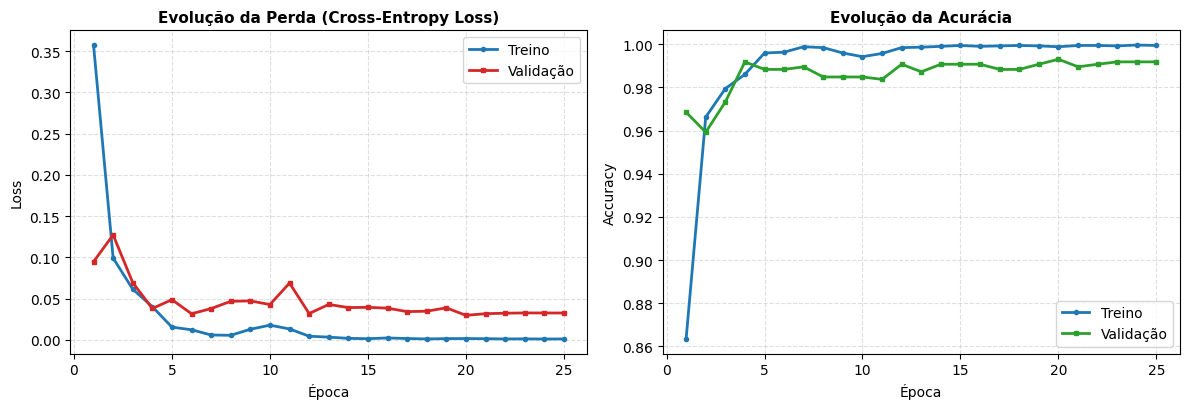

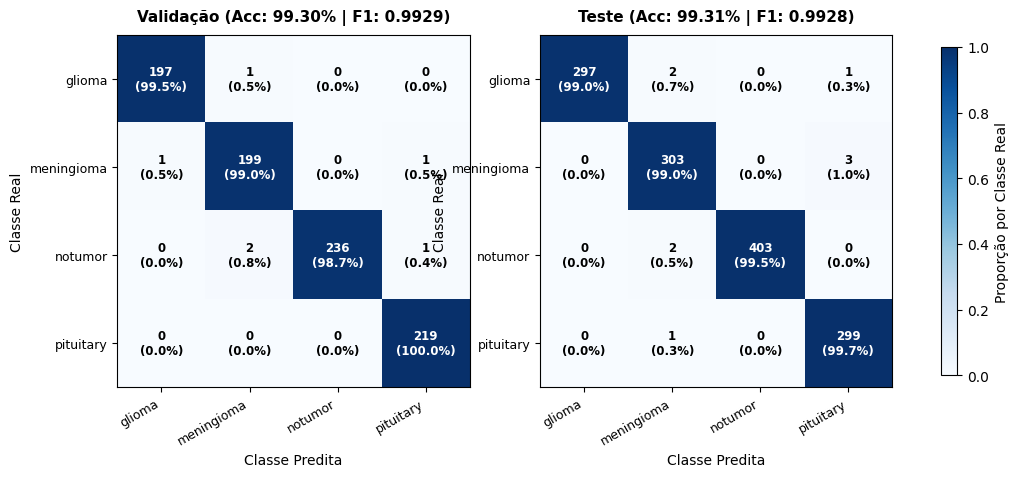

In [15]:
# 1. Gráfico das curvas de treinamento e validação em plt
df_hist = pd.DataFrame(historico)
fig, axes = plt.subplots(1, 2, figsize=(12, 4.2))

axes[0].plot(df_hist['epoca'], df_hist['train_loss'], label='Treino', color='#1f77b4', linewidth=2, marker='o', markersize=3)
axes[0].plot(df_hist['epoca'], df_hist['val_loss'], label='Validação', color='#d62728', linewidth=2, marker='s', markersize=3)
axes[0].set_title('Evolução da Perda (Cross-Entropy Loss)', fontsize=11, fontweight='bold')
axes[0].set_xlabel('Época')
axes[0].set_ylabel('Loss')
axes[0].grid(True, linestyle='--', alpha=0.4)
axes[0].legend(frameon=True)

axes[1].plot(df_hist['epoca'], df_hist['train_acc'], label='Treino', color='#1f77b4', linewidth=2, marker='o', markersize=3)
axes[1].plot(df_hist['epoca'], df_hist['val_acc'], label='Validação', color='#2ca02c', linewidth=2, marker='s', markersize=3)
axes[1].set_title('Evolução da Acurácia', fontsize=11, fontweight='bold')
axes[1].set_xlabel('Época')
axes[1].set_ylabel('Accuracy')
axes[1].grid(True, linestyle='--', alpha=0.4)
axes[1].legend(frameon=True)

plt.tight_layout()
plt.savefig(PROJETO_DIR / 'curvas_aprendizado_p1.png', dpi=300)
plt.show()

# 2. Função de avaliação e plotagem de matriz de confusão pura em plt
modelo.load_state_dict(torch.load(MODELO_PATH, map_location=device))
modelo.eval()

def avaliar_particao(loader, nome_split):
    preds, alvos, ids_lista = [], [], []
    with torch.no_grad():
        for x, y, idents in loader:
            x = x.to(device)
            logits = modelo(x)
            preds.extend(torch.argmax(logits, dim=1).cpu().numpy())
            alvos.extend(y.numpy())
            ids_lista.extend(idents)

    acc = accuracy_score(alvos, preds)
    prec = precision_score(alvos, preds, average='macro', zero_division=0)
    rec = recall_score(alvos, preds, average='macro', zero_division=0)
    f1 = f1_score(alvos, preds, average='macro', zero_division=0)
    cm = confusion_matrix(alvos, preds)

    relatorio = classification_report(alvos, preds, target_names=CLASSES, output_dict=True, zero_division=0)
    df_relatorio = pd.DataFrame(relatorio).transpose()

    resumo = {
        'Modelo': 'ConvNeXt-Atto',
        'Versao': VERSAO_MODELO,
        'Entrada': f'Imagem Completa ({ALTURA}x{LARGURA})',
        'Split': nome_split,
        'Amostras': len(alvos),
        'Accuracy': round(acc, 4),
        'Precision_Macro': round(prec, 4),
        'Recall_Macro': round(rec, 4),
        'F1_Macro': round(f1, 4)
    }
    df_predicoes = pd.DataFrame({
        'id': ids_lista,
        'classe_real': [IDX_TO_CLASS[i] for i in alvos],
        'classe_predita': [IDX_TO_CLASS[i] for i in preds],
        'acerto': [r == p for r, p in zip(alvos, preds)]
    })
    return resumo, df_relatorio, cm, df_predicoes

def plotar_matriz_plt(ax, cm, classes, titulo):
    cm_norm = cm.astype(float) / np.maximum(cm.sum(axis=1, keepdims=True), 1)
    im = ax.imshow(cm_norm, interpolation='nearest', cmap=plt.cm.Blues, vmin=0.0, vmax=1.0)
    ax.set_title(titulo, fontsize=11, fontweight='bold', pad=10)

    ticks = np.arange(len(classes))
    ax.set_xticks(ticks)
    ax.set_yticks(ticks)
    ax.set_xticklabels(classes, rotation=30, ha='right', fontsize=9)
    ax.set_yticklabels(classes, fontsize=9)
    ax.set_ylabel('Classe Real', fontsize=10)
    ax.set_xlabel('Classe Predita', fontsize=10)

    for i in range(cm.shape[0]):
        for j in range(cm.shape[1]):
            cor_texto = 'white' if cm_norm[i, j] > 0.55 else 'black'
            ax.text(
                j, i, f'{cm[i, j]}\n({cm_norm[i, j]*100:.1f}%)',
                ha='center', va='center', color=cor_texto, fontsize=8.5, fontweight='bold'
            )
    return im

resumo_val, rel_val, cm_val, pred_val = avaliar_particao(loader_val, 'Validacao')
resumo_test, rel_test, cm_test, pred_test = avaliar_particao(loader_teste, 'Teste')

# Figura lado a lado (Validação e Teste) inspirada em artigo científico
fig, axes = plt.subplots(1, 2, figsize=(12.5, 5.2))
plotar_matriz_plt(axes[0], cm_val, CLASSES, f"Validação (Acc: {resumo_val['Accuracy']:.2%} | F1: {resumo_val['F1_Macro']:.4f})")
im = plotar_matriz_plt(axes[1], cm_test, CLASSES, f"Teste (Acc: {resumo_test['Accuracy']:.2%} | F1: {resumo_test['F1_Macro']:.4f})")
fig.colorbar(im, ax=axes.ravel().tolist(), shrink=0.82, label='Proporção por Classe Real')
plt.savefig(PROJETO_DIR / 'matrizes_confusao_p1.png', dpi=300, bbox_inches='tight')
plt.show()

# Salva também arquivos individuais para cada split
for cm_atual, nome_arq, titulo_ind in [
    (cm_val, 'matriz_confusao_validacao.png', 'Matriz de Confusão — Validação (ConvNeXt-Atto)'),
    (cm_test, 'matriz_confusao_teste.png', 'Matriz de Confusão — Teste (ConvNeXt-Atto)')
]:
    fig_ind, ax_ind = plt.subplots(figsize=(5.8, 5.0))
    im_ind = plotar_matriz_plt(ax_ind, cm_atual, CLASSES, titulo_ind)
    fig_ind.colorbar(im_ind, ax=ax_ind, shrink=0.82)
    plt.tight_layout()
    plt.savefig(PROJETO_DIR / nome_arq, dpi=300)
    plt.close(fig_ind)


## 5. Exportação da planilha `P1_classificacao.xlsx` e inspeção de erros

Consolidamos todas as métricas na planilha **`P1_classificacao.xlsx`** no Google Drive (com abas separadas para resumo experimental, métricas por classe, matrizes de confusão, histórico de épocas e log de predições) e exibimos com `plt` os casos classificados incorretamente no conjunto de validação para apoiar a análise qualitativa.

Planilha exportada com sucesso para: /content/drive/MyDrive/Brain_Tumor_Project/P1_classificacao.xlsx


,Modelo,Versao,Entrada,Split,Amostras,Accuracy,Precision_Macro,Recall_Macro,F1_Macro
0,ConvNeXt-Atto,convnext_atto_full_img_v1,Imagem Completa (224x224),Validacao,857,0.9930,0.9928,0.9931,0.9929
1,ConvNeXt-Atto,convnext_atto_full_img_v1,Imagem Completa (224x224),Teste,1311,0.9931,0.9926,0.9930,0.9928


Total de erros na validação: 6 de 857 amostras.


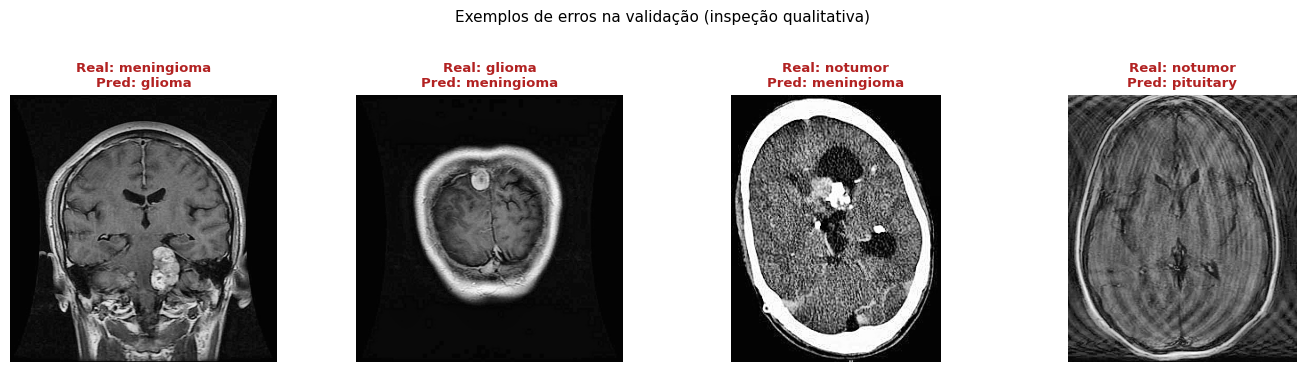

In [16]:
EXCEL_PATH = PROJETO_DIR / 'P1_classificacao.xlsx'
df_resumo = pd.DataFrame([resumo_val, resumo_test])
df_cm_val = pd.DataFrame(cm_val, index=CLASSES, columns=CLASSES)
df_cm_test = pd.DataFrame(cm_test, index=CLASSES, columns=CLASSES)

with pd.ExcelWriter(EXCEL_PATH, engine='openpyxl') as writer:
    df_resumo.to_excel(writer, sheet_name='Resumo_Experimental', index=False)
    rel_test.to_excel(writer, sheet_name='Metricas_Classe_Teste')
    rel_val.to_excel(writer, sheet_name='Metricas_Classe_Val')
    df_cm_test.to_excel(writer, sheet_name='Matriz_Confusao_Teste')
    df_cm_val.to_excel(writer, sheet_name='Matriz_Confusao_Val')
    df_hist.to_excel(writer, sheet_name='Historico_Epocas', index=False)
    pred_test.to_excel(writer, sheet_name='Predicoes_Teste', index=False)

print('Planilha exportada com sucesso para:', EXCEL_PATH)
display(df_resumo)

# Visualização qualitativa de erros na validação com plt
erros_val = pred_val[~pred_val['acerto']].merge(df_splits[['id', 'filepath']], on='id')
print(f'Total de erros na validação: {len(erros_val)} de {len(pred_val)} amostras.')

if len(erros_val) > 0:
    n_mostrar = min(len(erros_val), 4)
    fig, axes = plt.subplots(1, n_mostrar, figsize=(3.5 * n_mostrar, 3.6))
    if n_mostrar == 1:
        axes = [axes]
    for idx in range(n_mostrar):
        row = erros_val.iloc[idx]
        with Image.open(row['filepath']) as img:
            arr = np.asarray(img.convert('RGB'))
        axes[idx].imshow(arr)
        axes[idx].set_title(f"Real: {row['classe_real']}\nPred: {row['classe_predita']}", fontsize=9.5, color='#b22222', fontweight='bold')
        axes[idx].axis('off')
    plt.suptitle('Exemplos de erros na validação (inspeção qualitativa)', fontsize=11, y=1.02)
    plt.tight_layout()
    plt.savefig(PROJETO_DIR / 'erros_validacao_p1.png', dpi=300, bbox_inches='tight')
    plt.show()


## 6. Breve Análise dos Resultados Experimentais (P1)

* **Desempenho Global:** O modelo baseline `ConvNeXt-Atto` treinado com imagens completas ($224 \times 224$) atingiu **Acurácia de 99,30%** e **F1-Score (Macro) de 0,9929** (99,29%) no conjunto de validação (857 imagens, apenas 6 erros), e **Acurácia de 99,31%** com **F1-Score (Macro) de 0,9928** (99,28%) no conjunto de teste independente (1.311 imagens, apenas 9 erros).

* **Desempenho por Classe:** Observando a matriz de confusão do conjunto de teste, todas as classes superaram 99% de taxa de acerto (*recall*), com destaque para **`pituitary` (99,7%)** e **`notumor` (99,5%)**, seguidas por **`glioma` (99,0%)** e **`meningioma` (99,0%)**. Os poucos erros residuais concentraram-se principalmente entre **`meningioma` e `pituitary`** (4 casos) e **`glioma` e `meningioma`** (2 casos), o que se é esperado clinicamente, dado à proximidade anatômica e à sobreposição morfológica nas imagens completas sem recorte da região tumoral.

* **Conclusão para a Próxima Etapa:** Os resultados validam o pipeline reprodutível (`splits.csv`) e estabelecem a linha de base (*baseline*) quantitativa para avaliar o impacto da segmentação da região de interesse com o **SegFormer** na etapa seguinte.